# 4. Comparación de modelos con validación cruzada



In [1]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

import sys
from pathlib import Path

PROJECT_PATH = Path("..").resolve()
DATA_PATH = PROJECT_PATH / "data"
FIGURES_PATH = PROJECT_PATH / "figures"
sys.path.append(str(PROJECT_PATH))
RANDOM_STATE = 42

warnings.filterwarnings("ignore")
from predictor import TARGET, CATEGORICAL_FEATURES, engineer_features, encode_categories

## 4.1 Datos de train y folds
Stratified K-Fold aleatorio (k = 5): el conjunto de evaluación es una muestra aleatoria, no temporal.

In [2]:
train_reservations = pd.read_csv(DATA_PATH / "train.csv")
y_train = train_reservations[TARGET]
X_train = engineer_features(train_reservations)
train_categories = {column: sorted(X_train[column].unique()) for column in CATEGORICAL_FEATURES}
X_train_category = encode_categories(X_train, train_categories)
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

numeric_features = [column for column in X_train.columns if column not in CATEGORICAL_FEATURES]
print(X_train.shape)

(38273, 45)


## 4.2 Preprocesamiento por familia de modelo
- Lineales, Naive Bayes, KNN, árbol y RF: one-hot (categorías con < 20 casos agrupadas) + imputación + escalado, dentro del `Pipeline`.
- LightGBM y XGBoost: categóricas nativas (`category`). CatBoost: categóricas como texto.

In [3]:
one_hot_preprocessor = ColumnTransformer([
    ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), CATEGORICAL_FEATURES),
])


def one_hot_pipeline(classifier):
    return Pipeline([("preprocessing", one_hot_preprocessor), ("classifier", classifier)])


classifier_factories = {
    "Logistic Regression": (lambda: one_hot_pipeline(LogisticRegression(max_iter=2000)), X_train),
    "Naive Bayes": (lambda: one_hot_pipeline(GaussianNB()), X_train),
    "KNN": (lambda: one_hot_pipeline(KNeighborsClassifier(n_neighbors=15)), X_train),
    "Decision Tree": (lambda: one_hot_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)), X_train),
    "Random Forest": (lambda: one_hot_pipeline(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)), X_train),
    "XGBoost": (lambda: XGBClassifier(enable_categorical=True, tree_method="hist", random_state=RANDOM_STATE), X_train_category),
    "LightGBM": (lambda: LGBMClassifier(random_state=RANDOM_STATE, verbose=-1), X_train_category),
    "CatBoost": (lambda: CatBoostClassifier(cat_features=CATEGORICAL_FEATURES, random_seed=RANDOM_STATE, verbose=0), X_train),
}

## 4.3 Validación cruzada (hiperparámetros por defecto)
Métricas: balanced accuracy (la de la competencia, umbral 0.5) y ROC-AUC (ordenamiento, independiente del umbral).

In [4]:
def score_predictions(y_true, probabilities):
    return {"balanced_accuracy": balanced_accuracy_score(y_true, probabilities >= 0.5),
            "roc_auc": roc_auc_score(y_true, probabilities)}


def cross_validate_classifier(build_classifier, features):
    fold_scores = []
    for train_index, validation_index in stratified_kfold.split(features, y_train):
        classifier = build_classifier().fit(features.iloc[train_index], y_train.iloc[train_index])
        for split_name, split_index in [("train", train_index), ("validation", validation_index)]:
            probabilities = classifier.predict_proba(features.iloc[split_index])[:, 1]
            for metric, score in score_predictions(y_train.iloc[split_index], probabilities).items():
                fold_scores.append({"split": split_name, "metric": metric, "score": score})
    return pd.DataFrame(fold_scores).groupby(["metric", "split"])["score"].agg(["mean", "std"])


cv_results = []
for classifier_name, (build_classifier, features) in classifier_factories.items():
    fold_summary = cross_validate_classifier(build_classifier, features)
    for metric in ["balanced_accuracy", "roc_auc"]:
        cv_results.append({
            "classifier": classifier_name,
            "metric": metric,
            "train_mean": fold_summary.loc[(metric, "train"), "mean"],
            "validation_mean": fold_summary.loc[(metric, "validation"), "mean"],
            "validation_std": fold_summary.loc[(metric, "validation"), "std"],
        })
    print(f"{classifier_name:20s} BA = {fold_summary.loc[('balanced_accuracy', 'validation'), 'mean']:.4f}")

cv_results = pd.DataFrame(cv_results)
cv_results.to_csv(DATA_PATH / "cv_model_comparison.csv", index=False)

Logistic Regression  BA = 0.8145
Naive Bayes          BA = 0.7111
KNN                  BA = 0.8062
Decision Tree        BA = 0.8470
Random Forest        BA = 0.8777
XGBoost              BA = 0.8731
LightGBM             BA = 0.8711
CatBoost             BA = 0.8726


## 4.4 Comparación de clasificadores

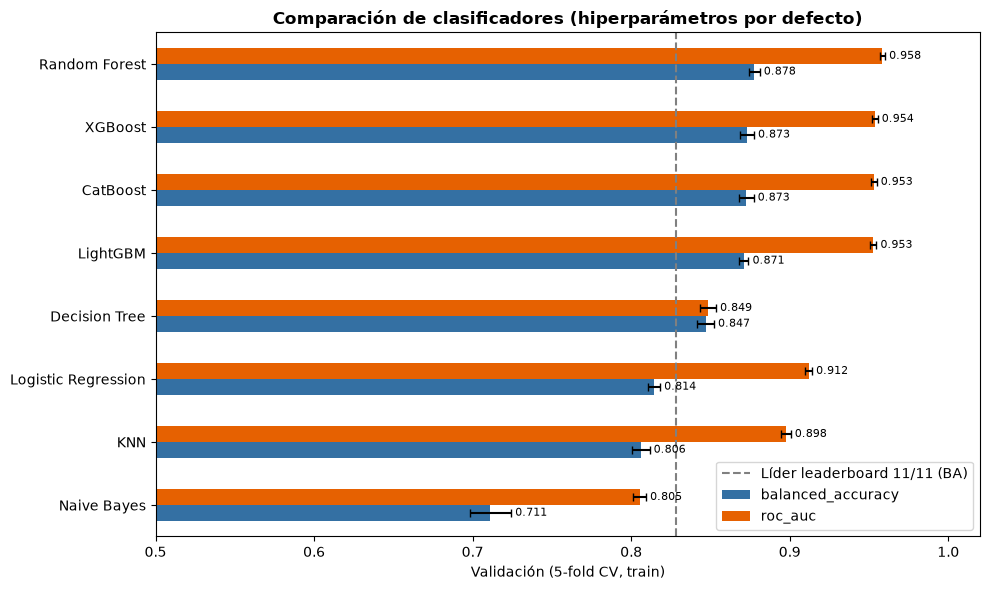

In [5]:
validation_means = cv_results.pivot(index="classifier", columns="metric", values="validation_mean").sort_values("balanced_accuracy")
validation_stds = cv_results.pivot(index="classifier", columns="metric", values="validation_std").loc[validation_means.index]

ax = validation_means.plot(kind="barh", xerr=validation_stds, capsize=3, figsize=(10, 6), color=["#3470a3", "#e66101"])
for bars in ax.containers:
    if hasattr(bars, "patches"):
        ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
ax.axvline(0.828, color="gray", linestyle="--", label="Líder leaderboard 11/11 (BA)")
ax.set_xlim(0.5, 1.02)
ax.set_xlabel("Validación (5-fold CV, train)")
ax.set_ylabel("")
ax.set_title("Comparación de clasificadores (hiperparámetros por defecto)", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "09_cv_classifier_comparison.png", dpi=300)
plt.show()

## 4.5 Brecha de generalización (train − validación)

In [6]:
cv_results["generalization_gap"] = cv_results["train_mean"] - cv_results["validation_mean"]
cv_results.pivot(index="classifier", columns="metric", values=["train_mean", "validation_mean", "generalization_gap"]).round(3)

train_mean           validation_mean          \
metric              balanced_accuracy roc_auc balanced_accuracy roc_auc   
classifier                                                                
CatBoost                        0.900   0.972             0.873   0.953   
Decision Tree                   0.997   1.000             0.847   0.849   
KNN                             0.836   0.926             0.806   0.898   
LightGBM                        0.895   0.970             0.871   0.953   
Logistic Regression             0.817   0.915             0.814   0.912   
Naive Bayes                     0.714   0.809             0.711   0.805   
Random Forest                   0.997   1.000             0.878   0.958   
XGBoost                         0.936   0.988             0.873   0.954   

                    generalization_gap          
metric               balanced_accuracy roc_auc  
classifier                                      
CatBoost                         0.028   0.019  
Decision Tree                    0.150   0.151  
KNN                              0.030   0.028  
LightGBM                         0.024   0.017  
Logistic Regression              0.003   0.003  
Naive Bayes                      0.003   0.004  
Random Forest                    0.119   0.041  
XGBoost                          0.063   0.034

## Conclusiones
- Por defecto el mejor es Random Forest (BA 0.878), pero memoriza train (BA train 0.997, brecha 0.12).
- Los tres boosting quedan muy cerca (0.871–0.873) con solo 100 árboles por defecto y menos brecha → más margen de ajuste.
- Se ajusta **LightGBM** (notebook 5): mismo nivel que XGBoost y CatBoost, categóricas nativas y el más rápido para buscar hiperparámetros. La combinación con los otros se evalúa en el notebook 6.
- Lineales, Naive Bayes y KNN quedan por debajo del líder del leaderboard (0.828) de la semana 2.
- SVM no se incluye: con ~38k filas y one-hot el costo es O(n²).